# 03 Scenario and Sensitivity Analysis

**Purpose:** Test how robust the city ranking is when key assumptions change.

**Method:** Change one assumption at a time (rent, hours, tax residency, food, transport) and compare weekly disposable income with the base case.

**Base case:** Hospitality, Level 1 casual, share room, tax resident, 24 hours per week.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from model_utils import *

tables = load_tables()
pd.options.display.float_format = "{:,.2f}".format

Matplotlib is building the font cache; this may take a moment.


## one-at-a-time scenarios

In [2]:
SCENARIOS = {
    "Base": {},
    "Rent +10%": {"rent_shock": 0.10},
    "12 hours/week": {"hours": scale_hours(12)},
    "48 hours/week (hypothetical)": {"hours": scale_hours(48)},
    "Foreign resident": {"residency": "Foreign resident"},
    "Food low ($49)": {"food": 49.0},
    "Food high ($150)": {"food": 150.0},
}

results = pd.DataFrame({
    name: {city: disposable_income(tables, city, **kw)["disposable"] for city in CITIES}
    for name, kw in SCENARIOS.items()
}).T[CITIES]

results

,Sydney,Melbourne,Brisbane,Perth,Adelaide
Base,29.61,195.11,169.61,168.21,200.21
Rent +10%,-24.09,155.81,125.41,124.81,167.11
12 hours/week,-333.34,-167.84,-193.34,-194.74,-162.74
48 hours/week (hypothetical),634.23,799.73,774.23,772.83,804.83
Foreign resident,-158.84,6.66,-18.84,-20.24,11.76
Food low ($49),99.61,265.11,239.61,238.21,340.21
Food high ($150),-1.39,164.11,138.61,137.21,239.21


## change vs base and city ranking

In [3]:
change = results - results.loc["Base"]
rank = results.rank(axis=1, ascending=False).astype(int)

display(change.round(2))
display(rank)

,Sydney,Melbourne,Brisbane,Perth,Adelaide
Base,0.00,0.00,0.00,0.00,0.00
Rent +10%,-53.70,-39.30,-44.20,-43.40,-33.10
12 hours/week,-362.95,-362.95,-362.95,-362.95,-362.95
48 hours/week (hypothetical),604.62,604.62,604.62,604.62,604.62
Foreign resident,-188.45,-188.45,-188.45,-188.45,-188.45
Food low ($49),70.00,70.00,70.00,70.00,140.00
Food high ($150),-31.00,-31.00,-31.00,-31.00,39.00


,Sydney,Melbourne,Brisbane,Perth,Adelaide
Base,5,2,3,4,1
Rent +10%,5,2,3,4,1
12 hours/week,5,2,3,4,1
48 hours/week (hypothetical),5,2,3,4,1
Foreign resident,5,2,3,4,1
Food low ($49),5,2,3,4,1
Food high ($150),5,2,3,4,1


## city-specific scenarios

In [4]:
base = {c: disposable_income(tables, c)["disposable"] for c in CITIES}

# Melbourne's half-price myki ends on 1 Jan 2027 (standard fare assumed to be double)
mel = disposable_income(tables, "Melbourne", transport=57.0)["disposable"]
# Adelaide food: outlier in source calculator ($189 vs $119 elsewhere)
ade = disposable_income(tables, "Adelaide", food=119.0)["disposable"]

print(f"Melbourne after myki promotion: {mel:,.2f} (base {base['Melbourne']:,.2f})")
print(f"Adelaide with food at $119:     {ade:,.2f} (base {base['Adelaide']:,.2f})")
print("Share room, base case ranking:", sorted(base, key=base.get, reverse=True))

Melbourne after myki promotion: 166.61 (base 195.11)
Adelaide with food at $119:     270.21 (base 200.21)
Share room, base case ranking: ['Adelaide', 'Melbourne', 'Brisbane', 'Perth', 'Sydney']


## break-even hours

In [5]:
def breakeven(city, housing):
    """Smallest weekly hours (same day mix) giving disposable income >= 0."""
    for h in range(1, 61):
        if disposable_income(tables, city, housing=housing, hours=scale_hours(h))["disposable"] >= 0:
            return h
    return None

breakeven_table = pd.DataFrame({
    housing: {city: breakeven(city, housing) for city in CITIES}
    for housing in ["Share room", "Living alone"]
})
breakeven_table

,Share room,Living alone
Sydney,23,32
Melbourne,18,25
Brisbane,19,26
Perth,19,27
Adelaide,18,25


## chart

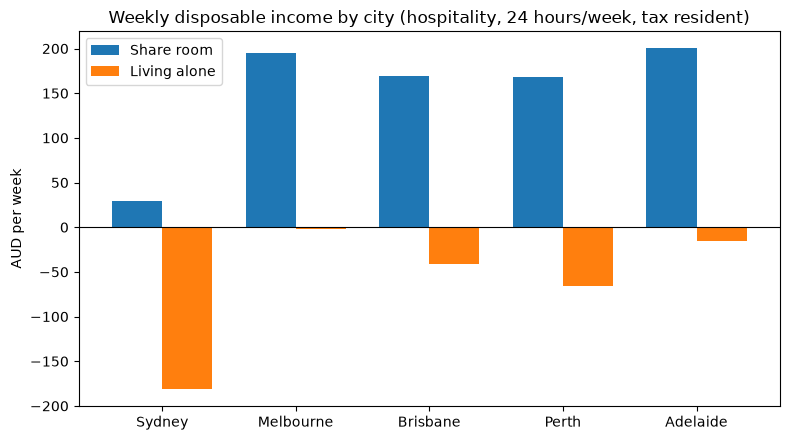

In [6]:
import os
os.makedirs("../report/figures", exist_ok=True)

plot = pd.DataFrame({
    housing: {c: disposable_income(tables, c, housing=housing)["disposable"] for c in CITIES}
    for housing in ["Share room", "Living alone"]
}).loc[CITIES]

ax = plot.plot(kind="bar", figsize=(8, 4.5), width=0.75)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Weekly disposable income by city (hospitality, 24 hours/week, tax resident)")
ax.set_ylabel("AUD per week")
ax.set_xlabel("")
ax.set_xticklabels(plot.index, rotation=0)
plt.tight_layout()
plt.savefig("../report/figures/disposable_income_by_city.png", dpi=200)
plt.show()

## Key findings
1. Adelaide ranks highest and Sydney lowest in every one-at-a-time scenario.
2. Tax residency status (resident vs foreign resident) changes weekly disposable income by about $188, far more than a 10% rent rise ($33 to $54).
3. Melbourne, Brisbane and Perth are within about $27 per week of each other; Melbourne drops to fourth once its half-price transport promotion ends.
4. Living alone requires 25 to 32 weekly hours to break even, above the 24 hours per week implied by a 48 hours per fortnight limit (to be verified against Home Affairs guidance).

## Limitations
Results are estimates based on award minimum wages and published averages, not actual student earnings.